# 2.4. Анализ факторов интереса к видеоиграм

В качестве двух показателей интереса аудитории используются число рекомендаций Steam и среднее число игроков за последние 12 месяцев, доступных в Steam Monthly Players.

Проверяются связи этих показателей с ценой, годом выхода и основным жанром игры. Нулевая гипотеза предполагает отсутствие статистической связи и различий между жанрами. Альтернативная гипотеза предполагает наличие хотя бы одной связи или различия.

Анализ выявляет статистические ассоциации и не доказывает причинное влияние. Межплатформенные совпадения по названиям в основной модели не используются.

In [1]:
from pathlib import Path
import json
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal, spearmanr
from IPython.display import display

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "notebooks").is_dir() and (path / "README.md").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Не удалось найти корень проекта.")

STEAM_PATH = ROOT / "processed" / "games" / "steam_games.parquet"
DATABASE_PATH = ROOT / "warehouse" / "games.duckdb"
OUTPUT_DIR = ROOT / "processed" / "analysis"
QUALITY_DIR = ROOT / "docs" / "data_quality"

for path in [STEAM_PATH, DATABASE_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Сначала запусти 2_3: {path}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
QUALITY_DIR.mkdir(parents=True, exist_ok=True)

analysis_start = time.perf_counter()

print("Корень проекта:", ROOT)

Корень проекта: C:\Users\Daniil\Documents\GitHub\gaming-data-analysis


## Подготовка игровой таблицы

Steam Monthly Players агрегируется по AppID за последние 12 месяцев, доступных в наборе. Благодаря этому к каталогу Steam присоединяется не более одной строки на игру.

Для каждого анализа ниже используются только записи без пропусков в нужных ему полях. Пропуски не заменяются нулями.

In [2]:
steam = pd.read_parquet(
    STEAM_PATH,
    columns=[
        "AppID", "name", "release_date", "price",
        "genres", "positive", "negative", "recommendations",
    ],
)
steam["AppID"] = steam["AppID"].astype("string")
steam["price"] = pd.to_numeric(steam["price"], errors="coerce")
steam["recommendations"] = pd.to_numeric(
    steam["recommendations"], errors="coerce"
)
steam["release_year"] = pd.to_datetime(
    steam["release_date"], errors="coerce"
).dt.year


def get_primary_genre(value):
    if not isinstance(value, str) or not value.strip():
        return None

    try:
        genres = json.loads(value)
    except json.JSONDecodeError:
        genres = value.split(",")

    if isinstance(genres, list) and genres:
        return str(genres[0]).strip() or None

    return None


steam["primary_genre"] = steam["genres"].map(get_primary_genre)

connection = duckdb.connect(str(DATABASE_PATH), read_only=True)

try:
    latest_month = connection.execute(
        "SELECT MAX(month) FROM steam_monthly_players"
    ).fetchone()[0]

    window_end = pd.Timestamp(latest_month)
    window_start = window_end - pd.DateOffset(months=11)

    monthly_players = connection.execute(
        """
        SELECT
            CAST(steam_appid AS VARCHAR) AS AppID,
            AVG(avg_players) AS avg_players_12m,
            COUNT(DISTINCT month) AS months_observed
        FROM steam_monthly_players
        WHERE month BETWEEN ? AND ?
        GROUP BY steam_appid
        """,
        [window_start.to_pydatetime(), window_end.to_pydatetime()],
    ).fetchdf()
finally:
    connection.close()

monthly_players["AppID"] = monthly_players["AppID"].astype("string")

analysis_df = steam.merge(
    monthly_players,
    on="AppID",
    how="left",
    validate="one_to_one",
)

reviews_total = analysis_df["positive"] + analysis_df["negative"]
analysis_df["positive_share"] = (
    analysis_df["positive"] / reviews_total.where(reviews_total > 0)
)

analysis_df.to_parquet(
    OUTPUT_DIR / "steam_game_analysis_2_4.parquet",
    index=False,
    compression="zstd",
)

print("Игр в каталоге Steam:", f"{len(analysis_df):,}")
print("Игр с данными игроков за период:", f"{analysis_df['avg_players_12m'].notna().sum():,}")
print("Окно Steam Monthly Players:", window_start.date(), "—", window_end.date())

display(
    analysis_df[
        [
            "price", "release_year", "primary_genre",
            "recommendations", "avg_players_12m", "positive_share",
        ]
    ].isna().sum().rename("missing_values").to_frame()
)

Игр в каталоге Steam: 150,466
Игр с данными игроков за период: 4,336
Окно Steam Monthly Players: 2024-10-01 — 2025-09-01


,missing_values
price,0
release_year,0
primary_genre,8437
recommendations,0
avg_players_12m,146130
positive_share,67380


## Описательный и статистический анализ

Корреляция Спирмена используется для оценки монотонных связей, менее чувствительных к сильной асимметрии показателей популярности. Для сравнения жанров применяется критерий Краскела — Уоллиса. В каждой игре для группировки используется первый жанр из исходного списка.

,feature,target,n,spearman_rho,p_value
0,price,recommendations,150466,0.208232,0.000000e+00
1,release_year,recommendations,150466,-0.244662,0.000000e+00
2,price,avg_players_12m,4336,0.103691,7.681300e-12
3,release_year,avg_players_12m,4336,0.075797,5.828061e-07


,groups_tested,kruskal_statistic,p_value
0,23,1944.761588,0.0


,games,median
primary_genre,,
Action,54946,0.0
Casual,32343,0.0
Adventure,29008,0.0
Indie,13995,0.0
Simulation,3228,0.0
RPG,2416,0.0
Strategy,2060,0.0
Free To Play,910,0.0
Racing,640,0.0


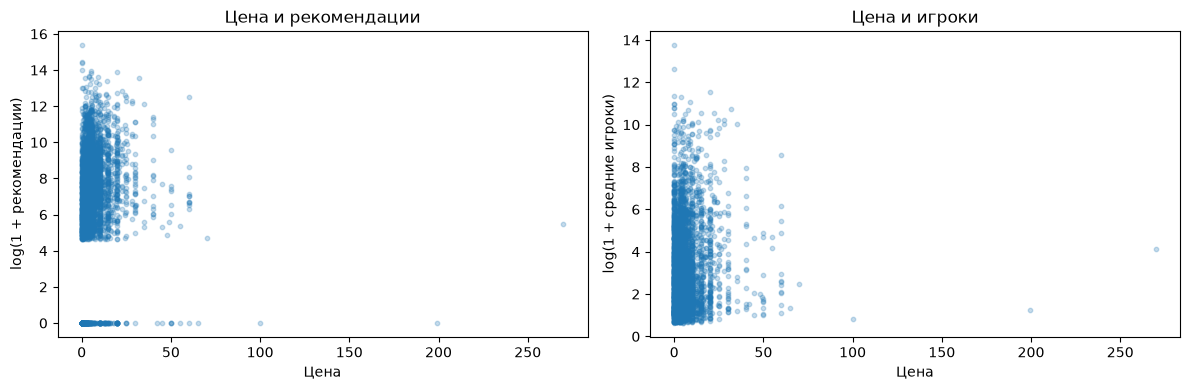

In [3]:
correlation_pairs = [
    ("price", "recommendations"),
    ("release_year", "recommendations"),
    ("price", "avg_players_12m"),
    ("release_year", "avg_players_12m"),
]

correlation_rows = []

for feature, target in correlation_pairs:
    sample = analysis_df[[feature, target]].dropna()
    sample = sample[(sample[feature] >= 0) & (sample[target] >= 0)]

    if len(sample) < 3:
        continue

    rho, p_value = spearmanr(sample[feature], sample[target])
    correlation_rows.append({
        "feature": feature,
        "target": target,
        "n": len(sample),
        "spearman_rho": rho,
        "p_value": p_value,
    })

correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(
    QUALITY_DIR / "correlations_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

genre_data = analysis_df.dropna(
    subset=["primary_genre", "recommendations"]
).copy()
genre_data = genre_data[genre_data["recommendations"] >= 0]
genre_data["log_recommendations"] = np.log1p(genre_data["recommendations"])

genre_summary = (
    genre_data.groupby("primary_genre")["log_recommendations"]
    .agg(games="size", median="median")
    .query("games >= 30")
    .sort_values("games", ascending=False)
)

genre_groups = [
    group["log_recommendations"].to_numpy()
    for _, group in genre_data.groupby("primary_genre")
    if len(group) >= 30
]

if len(genre_groups) >= 2:
    statistic, p_value = kruskal(*genre_groups)
    genre_test = pd.DataFrame([{
        "groups_tested": len(genre_groups),
        "kruskal_statistic": statistic,
        "p_value": p_value,
    }])
else:
    genre_test = pd.DataFrame()

genre_summary.to_csv(
    QUALITY_DIR / "genre_summary_2_4.csv",
    encoding="utf-8-sig",
)
genre_test.to_csv(
    QUALITY_DIR / "genre_test_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(correlations)
display(genre_test)
display(genre_summary.head(10))

plot_data = analysis_df.dropna(
    subset=["price", "recommendations", "avg_players_12m"]
)
plot_data = plot_data[
    (plot_data["price"] >= 0)
    & (plot_data["recommendations"] >= 0)
    & (plot_data["avg_players_12m"] >= 0)
]
plot_data = plot_data.sample(
    n=min(5_000, len(plot_data)),
    random_state=42,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    plot_data["price"],
    np.log1p(plot_data["recommendations"]),
    alpha=0.25,
    s=10,
)
axes[0].set(title="Цена и рекомендации", xlabel="Цена", ylabel="log(1 + рекомендации)")

axes[1].scatter(
    plot_data["price"],
    np.log1p(plot_data["avg_players_12m"]),
    alpha=0.25,
    s=10,
)
axes[1].set(title="Цена и игроки", xlabel="Цена", ylabel="log(1 + средние игроки)")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "price_popularity_2_4.png", dpi=150)
plt.show()
plt.close(fig)

## Модель машинного обучения

Random Forest оценивает, насколько цена, год выхода и основной жанр позволяют предсказывать показатели популярности. Для каждого целевого показателя строится отдельная модель.

Пропуски в выбранных признаках удаляются только для соответствующей модели. Для сокращения времени обучения используется случайная выборка до 50 000 игр с фиксированным seed. Метрики считаются на отложенной тестовой части и на логарифмической шкале целевого показателя.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

FEATURES = ["price", "release_year", "primary_genre"]


def fit_model(target):
    data = analysis_df[FEATURES + [target]].dropna().copy()
    data = data[(data["price"] >= 0) & (data[target] >= 0)]

    available_rows = len(data)
    data = data.sample(
        n=min(50_000, available_rows),
        random_state=42,
    )

    if len(data) < 100:
        print(f"{target}: недостаточно полных строк для модели")
        return None, pd.DataFrame()

    X = data[FEATURES]
    y = np.log1p(data[target])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
    )

    preparation = ColumnTransformer([
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["primary_genre"]),
        ("numeric", "passthrough", ["price", "release_year"]),
    ])

    model = Pipeline([
        ("prepare", preparation),
        ("forest", RandomForestRegressor(
            n_estimators=60,
            max_depth=14,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    started = time.perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    model_seconds = time.perf_counter() - started

    baseline = np.full(len(y_test), y_train.median())

    metrics = {
        "target": target,
        "available_rows": available_rows,
        "sample_rows": len(data),
        "test_rows": len(y_test),
        "mae_log1p": mean_absolute_error(y_test, predictions),
        "rmse_log1p": np.sqrt(mean_squared_error(y_test, predictions)),
        "r2_log1p": r2_score(y_test, predictions),
        "baseline_mae_log1p": mean_absolute_error(y_test, baseline),
        "training_seconds": model_seconds,
    }

    feature_names = model.named_steps["prepare"].get_feature_names_out()
    importance = pd.DataFrame({
        "target": target,
        "feature": feature_names,
        "importance": model.named_steps["forest"].feature_importances_,
    }).sort_values("importance", ascending=False)

    return metrics, importance


model_results = []
importance_results = []

for target in ["recommendations", "avg_players_12m"]:
    metrics, importance = fit_model(target)

    if metrics is not None:
        model_results.append(metrics)
        importance_results.append(importance)

model_metrics = pd.DataFrame(model_results)
feature_importance = pd.concat(importance_results, ignore_index=True)

model_metrics.to_csv(
    QUALITY_DIR / "model_metrics_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)
feature_importance.to_csv(
    QUALITY_DIR / "feature_importance_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(model_metrics)
display(
    feature_importance.groupby("target", group_keys=False)
    .head(10)
)

pd.DataFrame([{
    "stage": "analysis_2_4",
    "seconds": time.perf_counter() - analysis_start,
}]).to_csv(
    QUALITY_DIR / "processing_times_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

,target,available_rows,sample_rows,test_rows,mae_log1p,rmse_log1p,r2_log1p,baseline_mae_log1p,training_seconds
0,recommendations,142029,50000,10000,1.309024,2.134189,0.224747,1.000389,0.772850
1,avg_players_12m,4327,4327,866,1.382727,1.791880,0.089804,1.433888,0.094945


,target,feature,importance
0,recommendations,numeric__release_year,0.449298
1,recommendations,numeric__price,0.442858
2,recommendations,genre__primary_genre_Action,0.032425
3,recommendations,genre__primary_genre_Casual,0.029498
4,recommendations,genre__primary_genre_Adventure,0.021115
5,recommendations,genre__primary_genre_Indie,0.009042
6,recommendations,genre__primary_genre_Simulation,0.007631
7,recommendations,genre__primary_genre_RPG,0.006069
8,recommendations,genre__primary_genre_Strategy,0.001224
9,recommendations,genre__primary_genre_Racing,0.000430


## Интерпретация

При интерпретации учитываются размер эффекта, число наблюдений и сравнение модели с базовым прогнозом по медиане. Малое p-value само по себе не означает сильную связь. Важность признаков Random Forest показывает их вклад в предсказание, но не причинное влияние.

Ключевые ограничения: показатели Steam отражают активность на одной платформе; число рекомендаций является накопленным показателем; среднее число игроков рассчитано за доступное последнее 12-месячное окно; жанр для группировки представлен первым значением из списка. Для каждого результата указывается фактическое число использованных игр.